In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/hour.csv")
print(df.shape)
df.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
# combine the date and the hour into one datetime column
df["datetime"] = pd.to_datetime(df["dteday"]) + pd.to_timedelta(df["hr"], unit="h")
df = df.sort_values("datetime")
df = df.set_index("datetime")

print(df.index.min())
print(df.index.max())

2011-01-01 00:00:00
2012-12-31 23:00:00


In [4]:
# missing values in columns
print(df.isnull().sum())

# are any hours missing in the timeline?
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
print("Hours we have:", len(df))
print("Hours expected:", len(full_range))

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Hours we have: 17379
Hours expected: 17544


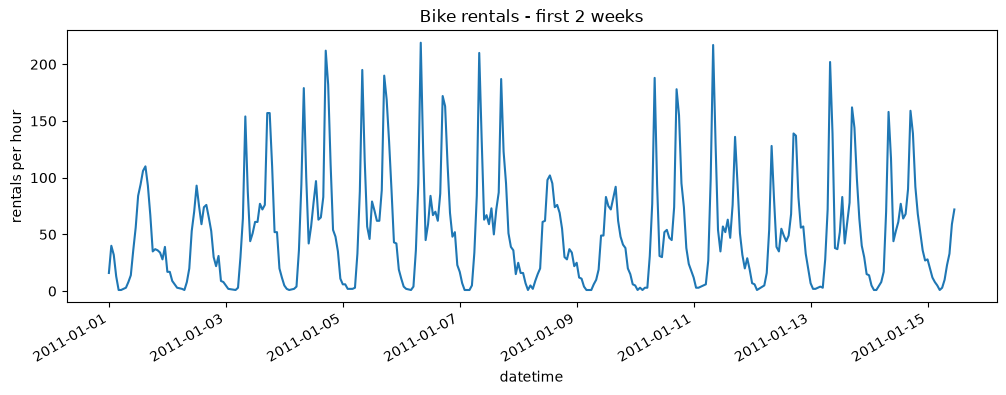

In [5]:
df["cnt"][:24 * 14].plot(figsize=(12, 4))
plt.title("Bike rentals - first 2 weeks")
plt.ylabel("rentals per hour")
plt.show()

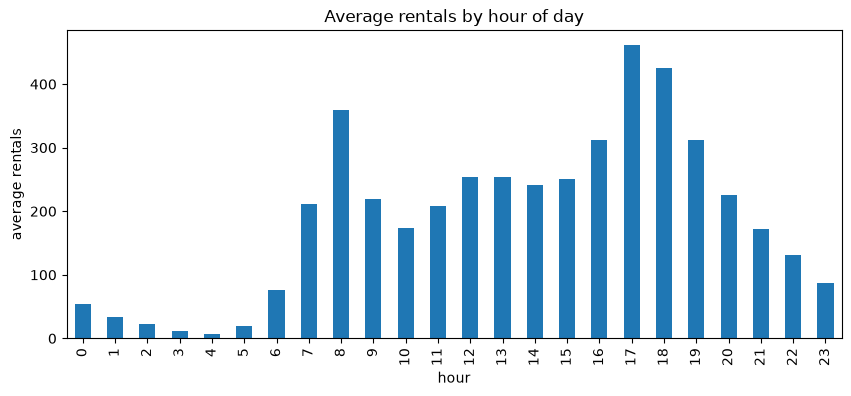

In [6]:
df.groupby("hr")["cnt"].mean().plot(kind="bar", figsize=(10, 4))
plt.title("Average rentals by hour of day")
plt.xlabel("hour")
plt.ylabel("average rentals")
plt.show()

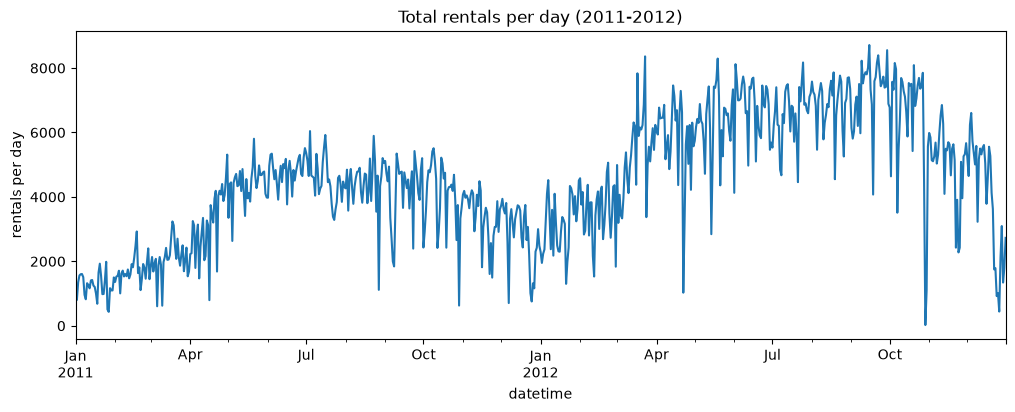

In [7]:
daily = df["cnt"].resample("D").sum()

daily.plot(figsize=(12, 4))
plt.title("Total rentals per day (2011-2012)")
plt.ylabel("rentals per day")
plt.savefig("../results/daily_total.png")
plt.show()

In [8]:
# 1. make a complete hourly timeline (no missing hours)
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(full_range)
df.index.name = "datetime"

# 2. missing hours = no rentals were logged, so we fill with 0 (our assumption)
for col in ["cnt", "casual", "registered"]:
    df[col] = df[col].fillna(0)

# 3. weather columns: copy the last known value
for col in ["weathersit", "temp", "atemp", "hum", "windspeed"]:
    df[col] = df[col].ffill()

# 4. calendar columns: take them from day.csv (it has every day)
day = pd.read_csv("../data/day.csv", parse_dates=["dteday"]).set_index("dteday")
for col in ["season", "holiday", "weekday", "workingday"]:
    df[col] = day[col].reindex(df.index.normalize()).values

df["hr"] = df.index.hour
df["mnth"] = df.index.month
df["yr"] = df.index.year - 2011

df = df.drop(columns=["instant", "dteday"])

print("Missing values:", df.isnull().sum().sum())   # should be 0
print("Rows:", len(df))                              # should be 17544

Missing values: 0
Rows: 17544


In [9]:
daily = df["cnt"].resample("D").sum()
print(daily.sort_values().head(5))

datetime
2012-10-29     22.0
2011-01-27    431.0
2012-12-26    441.0
2011-01-26    506.0
2011-03-06    605.0
Name: cnt, dtype: float64


In [10]:
df.to_csv("../data/clean_hourly.csv")